# Early At-Risk Student Prediction on OULAD — Version of Record

**One notebook, one run, the complete evidence base.** Consolidates and
deduplicates the previous notebook stack (starter + parity patch + multi-seed
patch + transformer/tuning/errors addendum + review-response + analysis pack).

**What was removed as redundant** (no information lost):
* The five-model tables, rank tests, and pairwise tests that were superseded
  the moment the transformer joined — every analysis now runs **once**, on
  all six models.
* The pseudoreplicated 25-block Friedman as an inferential tool — replaced by
  the corrected suite (seed-averaged Friedman as descriptive evidence; paired
  bootstrap + Holm-adjusted DeLong as primary inference); the 25-block
  statistic is printed once as a sensitivity line.
* The standalone demographics ablation — subsumed by the six-variant
  representation study.
* Five separate rebuilds of the week-8 context — replaced by one shared
  context cell.

**Structure:** 0 Setup · 1 Data · 2 Labels · 3 Clickstream (+vocabulary
check) · 4 Tabular · 5 Sequences+static · 6 Models · 7 Experiment (6×5×5) ·
8 Tables · 9 Week-8 context · 10 Statistics (bootstrap, Holm-DeLong,
Friedman, overlap, cluster) · 11 Figures (earliness + budget curves) ·
12 Tuning robustness · 13 Representation + fairness · 14 Calibration ·
15 Interpretability (RF SHAP + occlusion) · 16 Error analysis (FN + FP) ·
17 Output manifest.

**Runtime on a T4:** ~60 min (Secs. 0-8) + ~45 min (Sec. 12 tuning; set
`RUN_TUNING = False` to reuse recorded params and skip the search) +
~25 min (Secs. 13-16). Total ≈ 2h with tuning, ≈ 1.5h without.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Setup — the frozen protocol

In [ ]:
!pip -q install shap scikit-posthocs optuna

import os, re, time, zipfile, urllib.request
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import scikit_posthocs as sp
from scipy.stats import norm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score
import xgboost as xgb

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

KEY        = ["code_module", "code_presentation", "id_student"]
HORIZONS   = [4, 8, 12, 16, 20]        # prediction points (weeks)
SEEDS      = [0, 1, 2, 3, 4]
ALERT_RATE = 0.25                      # default alert budget
BUDGETS    = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
TRAIN_PRES = ["2013B", "2013J"]        # train cohorts
TEST_PRES  = ["2014B", "2014J"]        # year-ahead test cohorts
DEMO_CAT   = ["gender", "highest_education", "imd_band", "age_band", "disability"]
DEMO_NUM   = ["num_of_prev_attempts", "studied_credits"]
MODELS6    = ["LogReg", "RandomForest", "XGBoost", "LSTM", "GRU", "Transformer"]
RUN_TUNING = True                      # False -> reuse recorded tuned params

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [ ]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'drive', 'sample_data']


## 1. Data
Kaggle mirror via `kagglehub` (Alternatives: official OU download; Google
Drive chunked copy — commented).

In [ ]:
import kagglehub
DATA_DIR = kagglehub.dataset_download(
    "anlgrbz/student-demographics-online-education-dataoulad")

info    = pd.read_csv(os.path.join(DATA_DIR, "studentInfo.csv"))
reg     = pd.read_csv(os.path.join(DATA_DIR, "studentRegistration.csv"))
svle    = pd.read_csv(os.path.join(DATA_DIR, "studentVle.csv"))
vle     = pd.read_csv(os.path.join(DATA_DIR, "vle.csv"))
sassess = pd.read_csv(os.path.join(DATA_DIR, "studentAssessment.csv"))
assess  = pd.read_csv(os.path.join(DATA_DIR, "assessments.csv"))
print(f"{len(info):,} registrations, {len(svle):,} clickstream rows")

Using Colab cache for faster access to the 'student-demographics-online-education-dataoulad' dataset.
32,593 registrations, 10,655,280 clickstream rows


## 2. Labels and base cohort
At-risk = {Fail, Withdrawn}. Pre-course unregistrations excluded. At each
horizon, already-withdrawn students are removed (a deployed system scores
enrolled students only; prior withdrawal is tantamount to the label).

In [ ]:
df = info.merge(reg, on=KEY, how="left")
df = df[~(df.date_unregistration < 0)].copy()
df["at_risk"] = df.final_result.isin(["Fail", "Withdrawn"]).astype(int)
print(df.at_risk.value_counts(normalize=True).round(3))

at_risk
0    0.514
1    0.486
Name: proportion, dtype: float64


## 3. Clickstream preparation + vocabulary verification
Top-10 activity types kept as channels; remainder pooled. The verification
confirms the type list and demographic category vocabularies are identical
when derived from training presentations only — i.e., data-independent of
the test year (one footnote in the paper).

In [ ]:
if "atype" not in svle.columns:                     # idempotency guard
    svle = svle.merge(vle[["id_site", "activity_type"]].drop_duplicates("id_site"),
                      on="id_site", how="left")
    top_types = svle.activity_type.value_counts().head(10).index.tolist()
    svle["atype"] = np.where(svle.activity_type.isin(top_types),
                             svle.activity_type, "other")
    TYPES = top_types + ["other"]
    svle["week"] = (svle.date // 7).clip(lower=0)
print("Channels:", TYPES)

top10_train = svle[svle.code_presentation.isin(TRAIN_PRES)] \
                .activity_type.value_counts().head(10).index.tolist()
print("Top-10 types identical (train-only vs full):",
      set(top10_train) == set(TYPES) - {"other"})
vocab_ok = all(set(df[df.code_presentation.isin(TRAIN_PRES)][c].fillna("unknown"))
               == set(df[c].fillna("unknown")) for c in DEMO_CAT)
print("Demographic vocabularies identical (train vs full):", vocab_ok)

Channels: ['forumng', 'oucontent', 'subpage', 'homepage', 'quiz', 'resource', 'url', 'ouwiki', 'oucollaborate', 'externalquiz', 'other']
Top-10 types identical (train-only vs full): False
Demographic vocabularies identical (train vs full): True


## 4. Tabular features (classical models)
Aggregates of all events dated before day H·7 (pre-course included):
engagement (per-type/total clicks, active days, recency, OLS weekly slope),
assessments (count, mean score), one-hot demographics.

In [ ]:
def build_tabular(H, cohort):
    hdays = H * 7
    clicks = svle[svle.date < hdays]

    g = clicks.groupby(KEY)
    feats = g.agg(total_clicks=("sum_click", "sum"),
                  active_days=("date", "nunique"),
                  last_day=("date", "max")).reset_index()
    feats["days_since_last"] = hdays - feats.last_day
    feats = feats.drop(columns="last_day")

    pt = clicks.pivot_table(index=KEY, columns="atype", values="sum_click",
                            aggfunc="sum", fill_value=0)
    feats = feats.merge(pt.add_prefix("clk_").reset_index(), on=KEY, how="left")

    wk = clicks.groupby(KEY + ["week"]).sum_click.sum().reset_index()
    wk["w2"] = wk.week ** 2
    wk["wc"] = wk.week * wk.sum_click
    a = wk.groupby(KEY).agg(n=("week", "size"), sw=("week", "sum"),
                            sc=("sum_click", "sum"), sww=("w2", "sum"),
                            swc=("wc", "sum")).reset_index()
    den = a.n * a.sww - a.sw ** 2
    a["click_slope"] = np.where(den > 0, (a.n * a.swc - a.sw * a.sc) / den, 0.0)
    feats = feats.merge(a[KEY + ["click_slope"]], on=KEY, how="left")

    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[sa.date_submitted < hdays]
    ag = sa.groupby(KEY).agg(n_submitted=("score", "count"),
                             mean_score=("score", "mean")).reset_index()
    feats = feats.merge(ag, on=KEY, how="left")

    base = cohort.merge(feats, on=KEY, how="left")
    eng = [c for c in base.columns if c.startswith("clk_")] + \
          ["total_clicks", "active_days", "days_since_last",
           "click_slope", "n_submitted", "mean_score"]
    base["days_since_last"] = base["days_since_last"].fillna(hdays)
    base[eng] = base[eng].fillna(0)

    X = pd.concat([base[eng + DEMO_NUM],
                   pd.get_dummies(base[DEMO_CAT].fillna("unknown"))], axis=1)
    X.columns = [re.sub(r"\[|\]|<", "_", str(c)) for c in X.columns]
    return X.astype(np.float32), base.at_risk.values

## 5. Sequences + static features (deep models, exact parity)
(H × 13) weekly tensor: 11 log-scaled click channels + weekly assessment
mean-score and count channels; pre-course events bucketed into week 0 so the
event set matches the tabular filter exactly. Demographics as a standardized
static vector (late fusion).

In [ ]:
def build_sequences_v3(H, cohort):
    n_click = len(TYPES)
    X = np.zeros((len(cohort), H, n_click + 2), dtype=np.float32)
    ridx = cohort[KEY].copy()
    ridx["ridx"] = np.arange(len(ridx))

    clicks = svle[svle.date < H * 7].copy()
    clicks["wk"] = (clicks.date // 7).clip(lower=0)
    wk = clicks.groupby(KEY + ["wk", "atype"]).sum_click.sum().reset_index()
    wk = wk.merge(ridx, on=KEY, how="inner")
    t_idx = {t: i for i, t in enumerate(TYPES)}
    X[wk.ridx.values, wk.wk.values.astype(int), wk.atype.map(t_idx).values] = \
        np.log1p(wk.sum_click.values)

    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[sa.date_submitted < H * 7].copy()
    sa["wk"] = (sa.date_submitted // 7).clip(lower=0)
    ag = sa.groupby(KEY + ["wk"]).agg(mean_score=("score", "mean"),
                                      n_sub=("score", "count")).reset_index()
    ag = ag.merge(ridx, on=KEY, how="inner")
    w = ag.wk.values.astype(int)
    X[ag.ridx.values, w, n_click]     = ag.mean_score.fillna(0).values / 100.0
    X[ag.ridx.values, w, n_click + 1] = ag.n_sub.values
    return X


def build_static(cohort):
    global _STATIC
    if "_STATIC" not in globals():
        dummies = pd.get_dummies(df[DEMO_CAT].fillna("unknown"))
        _STATIC = pd.concat([df[KEY].reset_index(drop=True),
                             dummies.reset_index(drop=True),
                             df[DEMO_NUM].reset_index(drop=True)], axis=1)
    S = cohort[KEY].merge(_STATIC, on=KEY, how="left")
    return S.drop(columns=KEY).astype(np.float32).values

## 6. Models, training, metrics
All three sequence architectures (LSTM, GRU, transformer) share one seeded
training recipe: Adam 1e-3, class-weighted BCE, early stopping on a
training-side validation slice. The transformer's mean-pooled readout (vs.
last-state for RNNs) is a disclosed asymmetry.

In [ ]:
class RNNClassifierV2(nn.Module):
    def __init__(self, n_seq_feat, n_static, hidden=64, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_seq_feat, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_static, 64), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, x_seq, x_static):
        out, _ = self.rnn(x_seq)
        return self.head(torch.cat([out[:, -1], x_static], dim=1)).squeeze(-1)


class TransformerClassifier(nn.Module):
    def __init__(self, n_seq_feat, n_static, d_model=64, nhead=4,
                 nlayers=2, ff=128, dropout=0.1, max_len=32):
        super().__init__()
        self.proj = nn.Linear(n_seq_feat, d_model)
        self.pos = nn.Parameter(torch.zeros(1, max_len, d_model))
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                           dim_feedforward=ff, dropout=dropout,
                                           batch_first=True)
        self.enc = nn.TransformerEncoder(layer, num_layers=nlayers)
        self.head = nn.Sequential(nn.Linear(d_model + n_static, 64), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, x_seq, x_static):
        T = x_seq.shape[1]
        h = self.enc(self.proj(x_seq) + self.pos[:, :T])
        return self.head(torch.cat([h.mean(dim=1), x_static], dim=1)).squeeze(-1)


def make_seq_model(kind, n_seq_feat, n_static, hidden=64, dropout=0.1):
    if kind == "transformer":
        return TransformerClassifier(n_seq_feat, n_static,
                                     d_model=hidden, dropout=dropout)
    return RNNClassifierV2(n_seq_feat, n_static, hidden=hidden, cell=kind)


def train_seq_seeded(kind, Xtr, Str, ytr, Xte, Ste, seed,
                     hidden=64, dropout=0.1, lr=1e-3,
                     epochs=30, patience=5, batch=256, return_model=False):
    torch.manual_seed(seed)
    itr, ival = train_test_split(np.arange(len(ytr)), test_size=0.1,
                                 stratify=ytr, random_state=seed)
    ds = TensorDataset(torch.tensor(Xtr[itr]), torch.tensor(Str[itr]),
                       torch.tensor(ytr[itr], dtype=torch.float32))
    dl = DataLoader(ds, batch_size=batch, shuffle=True)
    model = make_seq_model(kind, Xtr.shape[2], Str.shape[1],
                           hidden=hidden, dropout=dropout).to(DEVICE)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    xv = torch.tensor(Xtr[ival]).to(DEVICE)
    sv = torch.tensor(Str[ival]).to(DEVICE)
    best_auc, best_state, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, sb, yb in dl:
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE), sb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(xv, sv)).cpu().numpy()
        auc = roc_auc_score(ytr[ival], pv)
        if auc > best_auc:
            best_auc, wait = auc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    if return_model:
        return model
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(Xte).to(DEVICE),
                                   torch.tensor(Ste).to(DEVICE))).cpu().numpy()


def recall_at_alert_rate(y_true, scores, rate=ALERT_RATE):
    k = max(1, int(rate * len(scores)))
    flagged = np.argsort(scores)[::-1][:k]
    return y_true[flagged].sum() / max(y_true.sum(), 1)


def delong_test(y_true, s1, s2):
    def _midrank(x):
        J = np.argsort(x); Z = x[J]; N = len(x)
        T = np.zeros(N); i = 0
        while i < N:
            j = i
            while j < N and Z[j] == Z[i]:
                j += 1
            T[i:j] = 0.5 * (i + j - 1) + 1
            i = j
        out = np.empty(N); out[J] = T
        return out
    pos = y_true == 1; neg = ~pos
    m, n = int(pos.sum()), int(neg.sum())
    aucs, v01s, v10s = [], [], []
    for s in (s1, s2):
        tx = _midrank(s[pos]); ty = _midrank(s[neg]); tz = _midrank(s)
        aucs.append((tz[pos].sum() - m * (m + 1) / 2) / (m * n))
        v01s.append((tz[pos] - tx) / n)
        v10s.append(1.0 - (tz[neg] - ty) / m)
    S = np.cov(np.vstack(v01s)) / m + np.cov(np.vstack(v10s)) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(max(var, 1e-12))
    return aucs[0], aucs[1], z, 2 * norm.sf(abs(z))


def holm(pvals):
    p = np.asarray(pvals, dtype=float); m = len(p)
    order = np.argsort(p); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj

## 7. The experiment: 6 models × 5 seeds × 5 horizons
Year-ahead holdout (train 2013 → test 2014). Data building is deterministic,
outside the seed loop; per-student test predictions are stored for every
downstream analysis. ~50-60 min.

In [ ]:
rows, preds_store, y_store = [], {}, {}

def fit_classical(name, seed, Xtr_, ytr_, Xte_):
    t0 = time.time()
    if name == "LogReg":
        m = LogisticRegression(max_iter=2000, class_weight="balanced")
    elif name == "RandomForest":
        m = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   random_state=seed, n_jobs=-1)
    else:
        m = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                              tree_method="hist", eval_metric="auc",
                              scale_pos_weight=(ytr_ == 0).sum() / (ytr_ == 1).sum(),
                              random_state=seed)
    m.fit(Xtr_, ytr_)
    return m.predict_proba(Xte_)[:, 1], time.time() - t0

for H in HORIZONS:
    print(f"\n=== Horizon: week {H} ===")
    hdays = H * 7
    cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= hdays)]
    cohort = cohort.reset_index(drop=True)
    tr = np.where(cohort.code_presentation.isin(TRAIN_PRES))[0]
    te = np.where(cohort.code_presentation.isin(TEST_PRES))[0]

    Xtab, y = build_tabular(H, cohort)
    Xseq = build_sequences_v3(H, cohort)
    S = StandardScaler().fit(build_static(cohort)[tr]) \
                        .transform(build_static(cohort)).astype(np.float32)
    Xtab_sc = StandardScaler().fit(Xtab.iloc[tr]).transform(Xtab)
    y_store[H] = y[te]
    print(f"train={len(tr):,} test={len(te):,}  "
          f"at-risk train={y[tr].mean():.3f} test={y[te].mean():.3f}")

    def record(name, seed, preds, secs):
        preds_store[(name, H, seed)] = preds
        rows.append(dict(model=name, week=H, seed=seed,
                         auc=roc_auc_score(y[te], preds),
                         recall_top25=recall_at_alert_rate(y[te], preds),
                         train_secs=secs))

    for seed in SEEDS:
        np.random.seed(seed)
        p, s = fit_classical("LogReg", seed, Xtab_sc[tr], y[tr], Xtab_sc[te])
        record("LogReg", seed, p, s)
        p, s = fit_classical("RandomForest", seed, Xtab.iloc[tr], y[tr], Xtab.iloc[te])
        record("RandomForest", seed, p, s)
        p, s = fit_classical("XGBoost", seed, Xtab.iloc[tr], y[tr], Xtab.iloc[te])
        record("XGBoost", seed, p, s)
        for kind, name in [("lstm", "LSTM"), ("gru", "GRU"),
                           ("transformer", "Transformer")]:
            t0 = time.time()
            p = train_seq_seeded(kind, Xseq[tr], S[tr], y[tr],
                                 Xseq[te], S[te], seed=seed)
            record(name, seed, p, time.time() - t0)
        print(f"  seed {seed} done")

res = pd.DataFrame(rows)
res.to_csv("results_6models.csv", index=False)
print(f"\nSaved {len(res)} rows -> results_6models.csv")



=== Horizon: week 4 ===
train=11,818 test=15,735  at-risk train=0.444 test=0.440
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 8 ===
train=11,434 test=15,098  at-risk train=0.425 test=0.416
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 12 ===
train=11,138 test=14,595  at-risk train=0.410 test=0.396
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 16 ===
train=10,783 test=14,158  at-risk train=0.391 test=0.377
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 20 ===
train=10,514 test=13,780  at-risk train=0.375 test=0.360
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

Saved 150 rows -> results_6models.csv


In [ ]:
import os
import shutil

# Folder in Google Drive
SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

res = pd.DataFrame(rows)

# Save results CSV
csv_path = os.path.join(SAVE_DIR, "results_6models.csv")
res.to_csv(csv_path, index=False)

print(f"\nSaved {len(res)} rows -> {csv_path}")

# Copy any generated PNG, PDF, CSV, or TXT files
for f in os.listdir("."):
    if f.endswith((".png", ".pdf", ".csv", ".txt")):
        shutil.copy(f, os.path.join(SAVE_DIR, f))

print(f"All generated result files copied to: {SAVE_DIR}")


Saved 150 rows -> /content/drive/MyDrive/SAMayu/results_6models.csv
All generated result files copied to: /content/drive/MyDrive/SAMayu


## 8. Paper tables (mean ± std over 5 seeds)

In [ ]:
summary = (res.groupby(["model", "week"])
              .agg(auc_mean=("auc", "mean"), auc_std=("auc", "std"),
                   r25_mean=("recall_top25", "mean"), r25_std=("recall_top25", "std"),
                   secs_mean=("train_secs", "mean")).round(4).reset_index())

def paper_pivot(mcol, scol):
    return (summary.assign(cell=lambda d: d[mcol].map("{:.3f}".format) + " ± " +
                           d[scol].map("{:.3f}".format))
            .pivot(index="model", columns="week", values="cell").loc[MODELS6])

print("TABLE I — AUC:")
display(paper_pivot("auc_mean", "auc_std"))
print("\nTABLE II — Recall @ 25% alert budget:")
display(paper_pivot("r25_mean", "r25_std"))
print("\nMean training seconds per fit:")
display(summary.pivot(index="model", columns="week", values="secs_mean").loc[MODELS6])

TABLE I — AUC:


week,4,8,12,16,20
model,,,,,
LogReg,0.710 ± 0.000,0.766 ± 0.000,0.809 ± 0.000,0.849 ± 0.000,0.878 ± 0.000
RandomForest,0.744 ± 0.001,0.792 ± 0.001,0.817 ± 0.001,0.854 ± 0.001,0.883 ± 0.000
XGBoost,0.737 ± 0.000,0.777 ± 0.000,0.805 ± 0.000,0.843 ± 0.000,0.877 ± 0.000
LSTM,0.735 ± 0.003,0.779 ± 0.002,0.803 ± 0.004,0.841 ± 0.003,0.870 ± 0.002
GRU,0.737 ± 0.005,0.784 ± 0.006,0.807 ± 0.003,0.846 ± 0.002,0.872 ± 0.001
Transformer,0.740 ± 0.004,0.793 ± 0.004,0.823 ± 0.004,0.851 ± 0.003,0.878 ± 0.003



TABLE II — Recall @ 25% alert budget:


week,4,8,12,16,20
model,,,,,
LogReg,0.397 ± 0.000,0.443 ± 0.000,0.488 ± 0.000,0.542 ± 0.000,0.587 ± 0.000
RandomForest,0.420 ± 0.001,0.469 ± 0.001,0.500 ± 0.001,0.552 ± 0.001,0.602 ± 0.001
XGBoost,0.411 ± 0.000,0.451 ± 0.000,0.490 ± 0.000,0.542 ± 0.000,0.595 ± 0.000
LSTM,0.414 ± 0.002,0.469 ± 0.004,0.506 ± 0.005,0.550 ± 0.003,0.591 ± 0.005
GRU,0.416 ± 0.004,0.475 ± 0.004,0.508 ± 0.004,0.554 ± 0.004,0.592 ± 0.004
Transformer,0.415 ± 0.006,0.477 ± 0.004,0.520 ± 0.003,0.550 ± 0.008,0.594 ± 0.005



Mean training seconds per fit:


week,4,8,12,16,20
model,,,,,
LogReg,0.1158,0.2062,0.1145,0.0314,0.0509
RandomForest,8.0582,7.7096,6.2273,8.1532,6.4949
XGBoost,1.2141,1.2064,1.1560,1.7100,1.7358
LSTM,7.3259,5.8862,6.9072,5.7072,6.2720
GRU,8.1406,6.6602,6.0169,6.5120,5.5749
Transformer,6.9009,6.5840,7.7627,7.3683,6.3818


## 9. Shared week-8 context
Built **once**; every week-8 analysis below (tuning, fairness,
representation, calibration, SHAP, errors) reuses these names. Never rebuilt
with generic names — this removes the silent-overwrite fragility of the old
patch stack.

In [ ]:
H8 = 8
cohort8 = df[df.date_unregistration.isna() | (df.date_unregistration >= H8 * 7)]
cohort8 = cohort8.reset_index(drop=True)
tr8 = np.where(cohort8.code_presentation.isin(TRAIN_PRES))[0]
te8 = np.where(cohort8.code_presentation.isin(TEST_PRES))[0]
Xtab8, y8 = build_tabular(H8, cohort8)
Xseq8 = build_sequences_v3(H8, cohort8)
S8 = StandardScaler().fit(build_static(cohort8)[tr8]) \
                     .transform(build_static(cohort8)).astype(np.float32)
Xtab8_sc = StandardScaler().fit(Xtab8.iloc[tr8]).transform(Xtab8)
yte8 = y8[te8]
avg8 = {m: np.mean([preds_store[(m, H8, s)] for s in SEEDS], axis=0)
        for m in MODELS6}
print(f"week-8 context: train={len(tr8):,} test={len(te8):,} "
      f"prevalence={yte8.mean():.3f}")

week-8 context: train=11,434 test=15,098 prevalence=0.416


## 10. Statistical inference (corrected)
**Primary:** paired student-level bootstrap (B=1000, shared resamples,
seed-averaged scores) for all 15 pairs × both metrics, and DeLong tests for
AUC with **Holm** correction over the family of 75 tests. **Descriptive:**
seed-averaged Friedman over 5 horizon blocks (the 25-block variant is
pseudoreplicated by deterministic models; printed once as sensitivity).
**Sensitivity:** returning-student overlap quantified, with a cluster
bootstrap by student at week 8 for the key pairs.

In [ ]:
# --- descriptive rank consistency ----------------------------------------
def friedman_seed_averaged(metric):
    piv = (res.groupby(["week", "model"])[metric].mean()
              .unstack("model")[MODELS6])
    stat, p = stats.friedmanchisquare(*[piv[c] for c in piv.columns])
    ranks = piv.rank(axis=1, ascending=False).mean().sort_values()
    print(f"[{metric}] seed-averaged Friedman (5 blocks): "
          f"chi2={stat:.2f}, p={p:.4f}")
    print(ranks.round(2).to_string(), "\n")

friedman_seed_averaged("auc")
friedman_seed_averaged("recall_top25")

piv25 = res.pivot_table(index=["week", "seed"], columns="model", values="auc")
s25, p25 = stats.friedmanchisquare(*[piv25[c] for c in piv25.columns])
print(f"Sensitivity (25-block, pseudoreplicated): chi2={s25:.2f}, p={p25:.2e}\n")

# --- primary inference: full pairwise bootstrap + Holm-DeLong -------------
PAIRS15 = list(combinations(MODELS6, 2))
rng = np.random.default_rng(11)
rows_stats = []
for H_ in HORIZONS:
    yte = y_store[H_]; n = len(yte)
    avg = {m: np.mean([preds_store[(m, H_, s)] for s in SEEDS], axis=0)
           for m in MODELS6}
    idx_mat = rng.integers(0, n, size=(1000, n))
    bs = {m: {"auc": np.empty(1000), "r25": np.empty(1000)} for m in MODELS6}
    for b in range(1000):
        idx = idx_mat[b]; yb = yte[idx]
        if yb.min() == yb.max():
            idx = np.arange(n); yb = yte
        for m in MODELS6:
            sb = avg[m][idx]
            bs[m]["auc"][b] = roc_auc_score(yb, sb)
            bs[m]["r25"][b] = recall_at_alert_rate(yb, sb)
    for a, bmod in PAIRS15:
        _, _, z, pdl = delong_test(yte, avg[a], avg[bmod])
        for metric in ["auc", "r25"]:
            d = bs[a][metric] - bs[bmod][metric]
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows_stats.append(dict(week=H_, pair=f"{a} - {bmod}", metric=metric,
                                   diff=round(d.mean(), 4),
                                   ci_lo=round(lo, 4), ci_hi=round(hi, 4),
                                   boot_separable=bool(lo > 0 or hi < 0),
                                   delong_p=round(pdl, 5) if metric == "auc" else np.nan))
    print(f"week {H_} bootstrap done")

allstats = pd.DataFrame(rows_stats)
am = allstats.metric == "auc"
allstats.loc[am, "delong_p_holm"] = holm(allstats.loc[am, "delong_p"].values).round(5)
allstats["delong_sig_holm"] = allstats.delong_p_holm < 0.05
allstats.to_csv("corrected_stats_full.csv", index=False)

print("\nAUC pairs surviving Holm (primary separability claims):")
display(allstats[am & allstats.delong_sig_holm]
        .sort_values(["week", "delong_p_holm"])
        [["week", "pair", "diff", "ci_lo", "ci_hi", "delong_p", "delong_p_holm"]])
print("Bootstrap-separable AUC pairs NOT surviving Holm (claims to soften):")
display(allstats[am & allstats.boot_separable & ~allstats.delong_sig_holm]
        [["week", "pair", "diff", "delong_p", "delong_p_holm"]])
print("Recall@25 separable pairs (bootstrap):")
display(allstats[(allstats.metric == "r25") & allstats.boot_separable]
        .sort_values("week")[["week", "pair", "diff", "ci_lo", "ci_hi"]])
print("\nCompact separability summary:")
display(allstats.groupby(["metric", "week"])
        .agg(separable=("boot_separable", "sum"),
             total=("boot_separable", "size")).reset_index())

[auc] seed-averaged Friedman (5 blocks): chi2=17.80, p=0.0032
model
RandomForest    1.4
Transformer     1.8
GRU             3.8
LogReg          4.0
XGBoost         4.6
LSTM            5.4 

[recall_top25] seed-averaged Friedman (5 blocks): chi2=15.17, p=0.0097
model
GRU             2.2
RandomForest    2.4
Transformer     2.4
LSTM            3.6
XGBoost         4.6
LogReg          5.8 

Sensitivity (25-block, pseudoreplicated): chi2=71.35, p=5.35e-14

week 4 bootstrap done
week 8 bootstrap done
week 12 bootstrap done
week 16 bootstrap done
week 20 bootstrap done

AUC pairs surviving Holm (primary separability claims):


,week,pair,diff,ci_lo,ci_hi,delong_p,delong_p_holm
0,4,LogReg - RandomForest,-0.0363,-0.0427,-0.0301,0.00000,0.00000
2,4,LogReg - XGBoost,-0.0268,-0.0333,-0.0208,0.00000,0.00000
4,4,LogReg - LSTM,-0.0282,-0.0339,-0.0224,0.00000,0.00000
6,4,LogReg - GRU,-0.0313,-0.0369,-0.0259,0.00000,0.00000
8,4,LogReg - Transformer,-0.0366,-0.0425,-0.0308,0.00000,0.00000
26,4,LSTM - Transformer,-0.0084,-0.0113,-0.0055,0.00000,0.00000
10,4,RandomForest - XGBoost,0.0095,0.0054,0.0135,0.00001,0.00045
24,4,LSTM - GRU,-0.0031,-0.0047,-0.0016,0.00006,0.00246
28,4,GRU - Transformer,-0.0052,-0.0083,-0.0023,0.00098,0.03234
22,4,XGBoost - Transformer,-0.0097,-0.0160,-0.0039,0.00118,0.03658


Bootstrap-separable AUC pairs NOT surviving Holm (claims to soften):


,week,pair,diff,delong_p,delong_p_holm
12,4,RandomForest - LSTM,0.0081,0.00605,0.16335
44,8,RandomForest - GRU,0.0056,0.04587,1.00000
92,16,LogReg - XGBoost,0.0058,0.00441,0.12348
104,16,RandomForest - GRU,0.0055,0.01794,0.44850
110,16,XGBoost - GRU,-0.0067,0.00422,0.12238
124,20,LogReg - LSTM,0.0051,0.03411,0.78453
142,20,XGBoost - Transformer,-0.0047,0.01724,0.44824
144,20,LSTM - GRU,-0.0014,0.03086,0.74064


Recall@25 separable pairs (bootstrap):


,week,pair,diff,ci_lo,ci_hi
1,4,LogReg - RandomForest,-0.0243,-0.0315,-0.0177
3,4,LogReg - XGBoost,-0.0140,-0.0215,-0.0068
5,4,LogReg - LSTM,-0.0160,-0.0229,-0.0096
7,4,LogReg - GRU,-0.0217,-0.0283,-0.0151
9,4,LogReg - Transformer,-0.0240,-0.0307,-0.0172
11,4,RandomForest - XGBoost,0.0103,0.0044,0.0161
13,4,RandomForest - LSTM,0.0083,0.0014,0.0149
21,4,XGBoost - GRU,-0.0076,-0.0146,-0.0003
23,4,XGBoost - Transformer,-0.0099,-0.0172,-0.0029
25,4,LSTM - GRU,-0.0057,-0.0090,-0.0023



Compact separability summary:


,metric,week,separable,total
0,auc,4,11,15
1,auc,8,13,15
2,auc,12,10,15
3,auc,16,11,15
4,auc,20,9,15
5,r25,4,11,15
6,r25,8,12,15
7,r25,12,12,15
8,r25,16,8,15
9,r25,20,6,15


In [ ]:
# --- overlap + cluster bootstrap by student (week 8) ----------------------
train_ids = set(cohort8.iloc[tr8].id_student)
sid = cohort8.iloc[te8].id_student.reset_index(drop=True)
overlap = sid.isin(train_ids).mean()
print(f"2014 test registrations from students seen in 2013 training: "
      f"{100*overlap:.1f}%")
m13, m14 = set(cohort8.iloc[tr8].code_module), set(cohort8.iloc[te8].code_module)
print(f"Module overlap: {sorted(m13 & m14)}; 2014-only: {sorted(m14 - m13) or 'none'}")

id_to_rows = pd.Series(range(len(sid))).groupby(sid.values).apply(np.array).to_dict()
uids = np.array(list(id_to_rows))
rng2 = np.random.default_rng(23)
clu = []
for a, bmod in [("RandomForest", "Transformer"), ("RandomForest", "GRU"),
                ("GRU", "Transformer")]:
    d = np.empty(500)
    for b in range(500):
        ids_b = rng2.choice(uids, size=len(uids), replace=True)
        idx = np.concatenate([id_to_rows[i] for i in ids_b])
        yb = yte8[idx]
        if yb.min() == yb.max():
            idx = np.arange(len(yte8)); yb = yte8
        d[b] = roc_auc_score(yb, avg8[a][idx]) - roc_auc_score(yb, avg8[bmod][idx])
    lo, hi = np.percentile(d, [2.5, 97.5])
    iid = allstats[(allstats.week == 8) & (allstats.metric == "auc") &
                   (allstats.pair == f"{a} - {bmod}")].iloc[0]
    clu.append(dict(pair=f"{a} - {bmod}",
                    cluster_ci=f"[{lo:.4f}, {hi:.4f}]",
                    iid_ci=f"[{iid.ci_lo:.4f}, {iid.ci_hi:.4f}]",
                    agree=bool((lo > 0 or hi < 0) == iid.boot_separable)))
cluster_cmp = pd.DataFrame(clu)
cluster_cmp.to_csv("cluster_bootstrap_week8.csv", index=False)
display(cluster_cmp)

2014 test registrations from students seen in 2013 training: 8.6%
Module overlap: ['AAA', 'BBB', 'DDD', 'EEE', 'FFF', 'GGG']; 2014-only: ['CCC']


,pair,cluster_ci,iid_ci,agree
0,RandomForest - Transformer,"[-0.0095, 0.0001]","[-0.0100, 0.0004]",True
1,RandomForest - GRU,"[0.0004, 0.0111]","[0.0001, 0.0114]",True
2,GRU - Transformer,"[-0.0133, -0.0069]","[-0.0134, -0.0071]",True


In [ ]:
cluster_cmp = pd.DataFrame(clu)

# Ensure save folder exists
os.makedirs(SAVE_DIR, exist_ok=True)

# Save locally
cluster_cmp.to_csv("cluster_bootstrap_week8.csv", index=False)

# Save to Google Drive
drive_path = os.path.join(SAVE_DIR, "cluster_bootstrap_week8.csv")
cluster_cmp.to_csv(drive_path, index=False)

print(f"Saved cluster bootstrap results to: {drive_path}")

display(cluster_cmp)

Saved cluster bootstrap results to: /content/drive/MyDrive/SAMayu/cluster_bootstrap_week8.csv


,pair,cluster_ci,iid_ci,agree
0,RandomForest - Transformer,"[-0.0095, 0.0001]","[-0.0100, 0.0004]",True
1,RandomForest - GRU,"[0.0004, 0.0111]","[0.0001, 0.0114]",True
2,GRU - Transformer,"[-0.0133, -0.0069]","[-0.0134, -0.0071]",True


## 11. Figures: earliness + intervention-budget curves

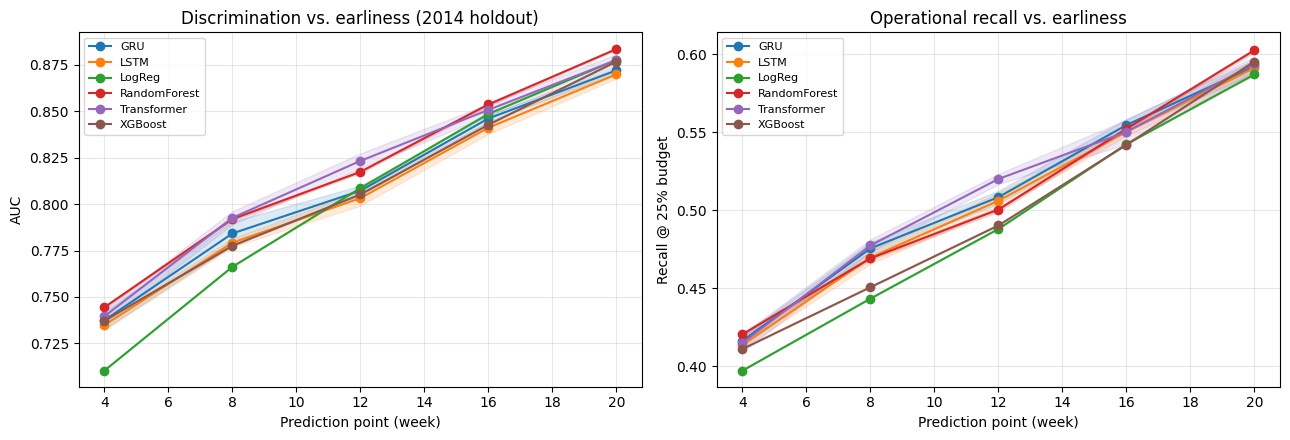

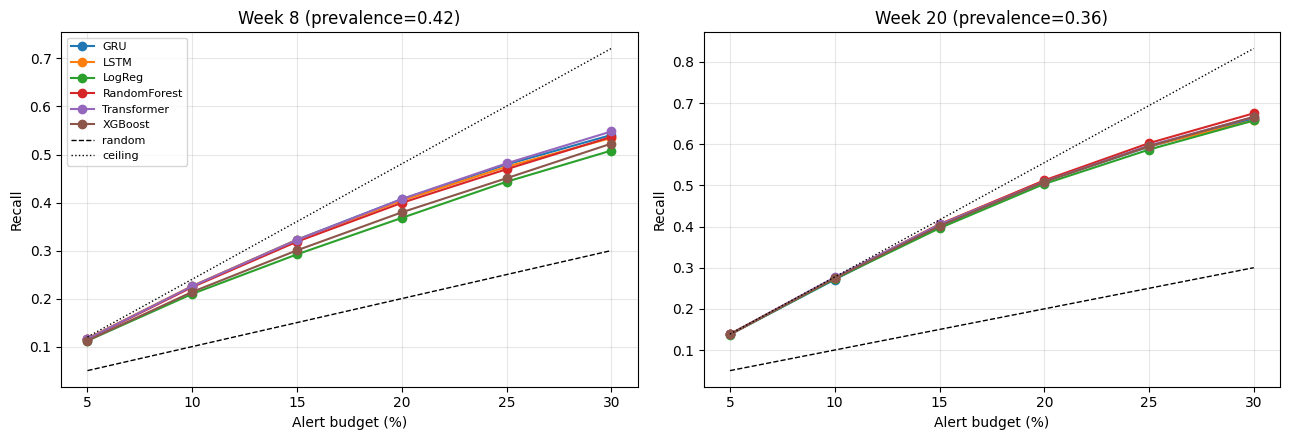

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, g in res.groupby("model"):
    for ax, metric in zip(axes, ["auc", "recall_top25"]):
        gm = g.groupby("week")[metric].agg(["mean", "std"]).reset_index()
        line, = ax.plot(gm.week, gm["mean"], marker="o", label=m)
        ax.fill_between(gm.week, gm["mean"] - gm["std"], gm["mean"] + gm["std"],
                        alpha=0.15, color=line.get_color())
axes[0].set(xlabel="Prediction point (week)", ylabel="AUC",
            title="Discrimination vs. earliness (2014 holdout)")
axes[1].set(xlabel="Prediction point (week)", ylabel="Recall @ 25% budget",
            title="Operational recall vs. earliness")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("earliness_figure.png", dpi=300, bbox_inches="tight")
plt.show()

rows_b = []
for H_ in HORIZONS:
    yte = y_store[H_]
    for m in MODELS6:
        avg = np.mean([preds_store[(m, H_, s)] for s in SEEDS], axis=0)
        for b in BUDGETS:
            rows_b.append(dict(model=m, week=H_, budget=b,
                               recall=round(recall_at_alert_rate(yte, avg, rate=b), 4)))
topk = pd.DataFrame(rows_b)
topk.to_csv("topk_budget_curves.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, H_ in zip(axes, [8, 20]):
    yte = y_store[H_]; pi = yte.mean()
    for m, g in topk[topk.week == H_].groupby("model"):
        ax.plot(g.budget * 100, g.recall, marker="o", label=m)
    bb = np.array(BUDGETS)
    ax.plot(bb * 100, bb, "k--", lw=1, label="random")
    ax.plot(bb * 100, np.minimum(1, bb / pi), "k:", lw=1, label="ceiling")
    ax.set(xlabel="Alert budget (%)", ylabel="Recall",
           title=f"Week {H_} (prevalence={pi:.2f})")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("budget_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# --- Save generated figures and CSV files to Google Drive -------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "earliness_figure.png",
    "topk_budget_curves.csv",
    "budget_curves.png"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("All generated files saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/earliness_figure.png
Saved: /content/drive/MyDrive/SAMayu/topk_budget_curves.csv
Saved: /content/drive/MyDrive/SAMayu/budget_curves.png
All generated files saved to SAMayu folder.


## 12. Tuning robustness (week 8) + tuned-pair significance
30 TPE trials/model, identical budget; objective = validation AUC on a 15%
training-side slice. Best configs refit on the full training cohort and
tested once on 2014 (deep models 3-seed averaged — disclosed). Then paired
bootstrap + DeLong on the tuned pairs. Set `RUN_TUNING=False` to reuse
recorded params. ~45 min with tuning.

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

BEST_FALLBACK = {
    "LogReg":       {"C": 10.692772658181882},
    "RandomForest": {"n_estimators": 249, "max_depth": 11,
                     "min_samples_leaf": 5, "max_features": 0.3},
    "XGBoost":      {"n_estimators": 264, "max_depth": 4,
                     "learning_rate": 0.03902632434291149,
                     "subsample": 0.7485680253906761,
                     "colsample_bytree": 0.7317110503448141,
                     "min_child_weight": 3},
    "LSTM":         {"hidden": 64, "lr": 0.0019042540441814766, "dropout": 0.21817437566895256},
    "GRU":          {"hidden": 64, "lr": 0.001949350156265576,  "dropout": 0.29429419751862523},
    "Transformer":  {"hidden": 128, "lr": 0.00017201983790521383, "dropout": 0.21290798777930844},
}

tr_fit, tr_val = train_test_split(tr8, test_size=0.15, stratify=y8[tr8],
                                  random_state=0)

def val_preds_seq(kind, hidden, lr, dropout, epochs=25, patience=4, seed=0):
    torch.manual_seed(seed)
    ds = TensorDataset(torch.tensor(Xseq8[tr_fit]), torch.tensor(S8[tr_fit]),
                       torch.tensor(y8[tr_fit], dtype=torch.float32))
    dl = DataLoader(ds, batch_size=256, shuffle=True)
    model = make_seq_model(kind, Xseq8.shape[2], S8.shape[1],
                           hidden=hidden, dropout=dropout).to(DEVICE)
    pos_w = torch.tensor((y8[tr_fit] == 0).sum() / max((y8[tr_fit] == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    xv = torch.tensor(Xseq8[tr_val]).to(DEVICE)
    sv = torch.tensor(S8[tr_val]).to(DEVICE)
    best_auc, best_pv, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, sb, yb in dl:
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE), sb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(xv, sv)).cpu().numpy()
        auc = roc_auc_score(y8[tr_val], pv)
        if auc > best_auc:
            best_auc, best_pv, wait = auc, pv, 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best_pv

if RUN_TUNING:
    def tune(obj, name):
        st = optuna.create_study(direction="maximize",
                                 sampler=optuna.samplers.TPESampler(seed=0))
        st.optimize(obj, n_trials=30, show_progress_bar=False)
        print(f"{name:12s} best val AUC={st.best_value:.4f}  {st.best_params}")
        return st.best_params

    best = {}
    best["LogReg"] = tune(lambda t: roc_auc_score(
        y8[tr_val], LogisticRegression(C=t.suggest_float("C", 1e-3, 1e2, log=True),
                                       max_iter=2000, class_weight="balanced")
        .fit(Xtab8_sc[tr_fit], y8[tr_fit]).predict_proba(Xtab8_sc[tr_val])[:, 1]),
        "LogReg")
    best["RandomForest"] = tune(lambda t: roc_auc_score(
        y8[tr_val], RandomForestClassifier(
            n_estimators=t.suggest_int("n_estimators", 100, 500),
            max_depth=t.suggest_int("max_depth", 4, 24),
            min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10),
            max_features=t.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
            class_weight="balanced", random_state=0, n_jobs=-1)
        .fit(Xtab8.iloc[tr_fit], y8[tr_fit]).predict_proba(Xtab8.iloc[tr_val])[:, 1]),
        "RandomForest")
    best["XGBoost"] = tune(lambda t: roc_auc_score(
        y8[tr_val], xgb.XGBClassifier(
            n_estimators=t.suggest_int("n_estimators", 100, 600),
            max_depth=t.suggest_int("max_depth", 3, 9),
            learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
            subsample=t.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=t.suggest_float("colsample_bytree", 0.6, 1.0),
            min_child_weight=t.suggest_int("min_child_weight", 1, 10),
            tree_method="hist", eval_metric="auc", random_state=0,
            scale_pos_weight=(y8[tr_fit] == 0).sum() / (y8[tr_fit] == 1).sum())
        .fit(Xtab8.iloc[tr_fit], y8[tr_fit]).predict_proba(Xtab8.iloc[tr_val])[:, 1]),
        "XGBoost")
    for kind, name in [("lstm", "LSTM"), ("gru", "GRU"),
                       ("transformer", "Transformer")]:
        best[name] = tune(lambda t, k=kind: roc_auc_score(
            y8[tr_val], val_preds_seq(
                k, hidden=t.suggest_categorical("hidden", [32, 64, 128]),
                lr=t.suggest_float("lr", 1e-4, 3e-3, log=True),
                dropout=t.suggest_float("dropout", 0.0, 0.4))), name)
else:
    best = BEST_FALLBACK
    print("RUN_TUNING=False -> using recorded tuned parameters")

LogReg       best val AUC=0.7726  {'C': 10.692772658181882}
RandomForest best val AUC=0.8181  {'n_estimators': 249, 'max_depth': 11, 'min_samples_leaf': 5, 'max_features': 0.3}
XGBoost      best val AUC=0.8224  {'n_estimators': 264, 'max_depth': 4, 'learning_rate': 0.03902632434291149, 'subsample': 0.7485680253906761, 'colsample_bytree': 0.7317110503448141, 'min_child_weight': 3}
LSTM         best val AUC=0.8151  {'hidden': 64, 'lr': 0.0019042540441814766, 'dropout': 0.21817437566895256}
GRU          best val AUC=0.8170  {'hidden': 64, 'lr': 0.001949350156265576, 'dropout': 0.29429419751862523}
Transformer  best val AUC=0.8151  {'hidden': 128, 'lr': 0.00017201983790521383, 'dropout': 0.21290798777930844}


In [ ]:
# --- refit tuned configs on full train; evaluate + significance -----------
tuned_preds = {}
m = LogisticRegression(C=best["LogReg"]["C"], max_iter=2000, class_weight="balanced")
m.fit(Xtab8_sc[tr8], y8[tr8]); tuned_preds["LogReg"] = m.predict_proba(Xtab8_sc[te8])[:, 1]
m = RandomForestClassifier(**best["RandomForest"], class_weight="balanced",
                           random_state=0, n_jobs=-1)
m.fit(Xtab8.iloc[tr8], y8[tr8]); tuned_preds["RandomForest"] = m.predict_proba(Xtab8.iloc[te8])[:, 1]
m = xgb.XGBClassifier(**best["XGBoost"], tree_method="hist", eval_metric="auc",
                      random_state=0,
                      scale_pos_weight=(y8[tr8] == 0).sum() / (y8[tr8] == 1).sum())
m.fit(Xtab8.iloc[tr8], y8[tr8]); tuned_preds["XGBoost"] = m.predict_proba(Xtab8.iloc[te8])[:, 1]
for kind, name in [("lstm", "LSTM"), ("gru", "GRU"), ("transformer", "Transformer")]:
    p3 = [train_seq_seeded(kind, Xseq8[tr8], S8[tr8], y8[tr8], Xseq8[te8], S8[te8],
                           seed=s, hidden=best[name]["hidden"], lr=best[name]["lr"],
                           dropout=best[name]["dropout"]) for s in [0, 1, 2]]
    tuned_preds[name] = np.mean(p3, axis=0)

tuned_tbl = pd.DataFrame([dict(model=m_, auc_tuned=roc_auc_score(yte8, tuned_preds[m_]),
                               r25_tuned=recall_at_alert_rate(yte8, tuned_preds[m_]))
                          for m_ in MODELS6]).set_index("model")
default8 = (res[res.week == 8].groupby("model")
            .agg(auc_default=("auc", "mean"), r25_default=("recall_top25", "mean")))
cmp = default8.join(tuned_tbl).round(4).sort_values("auc_tuned", ascending=False)
cmp.to_csv("tuning_check_week8.csv")
display(cmp)

rng3 = np.random.default_rng(7)
n = len(yte8)
idx_mat = rng3.integers(0, n, size=(1000, n))
b_auc = {m_: np.empty(1000) for m_ in MODELS6}
for b in range(1000):
    idx = idx_mat[b]; yb = yte8[idx]
    if yb.min() == yb.max():
        idx = np.arange(n); yb = yte8
    for m_ in MODELS6:
        b_auc[m_][b] = roc_auc_score(yb, tuned_preds[m_][idx])
tsig = []
for a, bmod in combinations(MODELS6, 2):
    d = b_auc[a] - b_auc[bmod]
    lo, hi = np.percentile(d, [2.5, 97.5])
    _, _, z, pdl = delong_test(yte8, tuned_preds[a], tuned_preds[bmod])
    tsig.append(dict(pair=f"{a} - {bmod}", diff=round(d.mean(), 4),
                     ci_lo=round(lo, 4), ci_hi=round(hi, 4),
                     delong_p=round(pdl, 4), separable=bool(lo > 0 or hi < 0)))
tuned_sig = pd.DataFrame(tsig).sort_values("delong_p")
tuned_sig.to_csv("tuned_significance_week8.csv", index=False)
print("Tuned pairwise tests (leaders first):")
display(tuned_sig.head(8))

,auc_default,r25_default,auc_tuned,r25_tuned
model,,,,
XGBoost,0.7775,0.4506,0.7967,0.4636
RandomForest,0.7919,0.4691,0.7950,0.4593
Transformer,0.7926,0.4773,0.7905,0.4762
GRU,0.7842,0.4754,0.7861,0.4770
LSTM,0.7792,0.4695,0.7828,0.4773
LogReg,0.7662,0.4433,0.7662,0.4433


Tuned pairwise tests (leaders first):


,pair,diff,ci_lo,ci_hi,delong_p,separable
0,LogReg - RandomForest,-0.0288,-0.0344,-0.0234,0.0,True
1,LogReg - XGBoost,-0.0305,-0.0355,-0.0256,0.0,True
2,LogReg - LSTM,-0.0165,-0.0234,-0.0101,0.0,True
3,LogReg - GRU,-0.0198,-0.0270,-0.0131,0.0,True
4,LogReg - Transformer,-0.0242,-0.0301,-0.0185,0.0,True
6,RandomForest - LSTM,0.0123,0.0067,0.0179,0.0,True
13,LSTM - Transformer,-0.0077,-0.0114,-0.0037,0.0,True
9,XGBoost - LSTM,0.0139,0.0086,0.0191,0.0,True


In [ ]:
# --- Save tuning evaluation outputs to Google Drive -------------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "tuning_check_week8.csv",
    "tuned_significance_week8.csv"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("Tuning evaluation files saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/tuning_check_week8.csv
Saved: /content/drive/MyDrive/SAMayu/tuned_significance_week8.csv
Tuning evaluation files saved to SAMayu folder.


## 13. Representation study + fairness subgroups (week 8)
Six source variants (D / A / C / C+A / C+D / All) for RF and the transformer
— the D-vs-no-D contrast doubles as the demographics ablation, quantifying
the equity–accuracy trade-off. Then subgroup flag rates and recall under the
operational global 25% alert list, reported descriptively.

In [ ]:
CLICK_COLS = [c for c in Xtab8.columns if c.startswith("clk_")] + \
             ["total_clicks", "active_days", "days_since_last", "click_slope"]
ASSESS_COLS = ["n_submitted", "mean_score"]
DEMO_COLS = [c for c in Xtab8.columns if c not in CLICK_COLS + ASSESS_COLS]
N_CLICK_CH = len(TYPES)
S0 = np.zeros((len(cohort8), 1), dtype=np.float32)

VARIANTS = {
    "D only": (DEMO_COLS,                True,  True,  True),
    "A only": (ASSESS_COLS,              True,  False, False),
    "C only": (CLICK_COLS,               False, True,  False),
    "C + A":  (CLICK_COLS + ASSESS_COLS, False, False, False),
    "C + D":  (CLICK_COLS + DEMO_COLS,   False, True,  True),
    "All":    (list(Xtab8.columns),      False, False, True),
}
rep_rows = []
for vname, (cols, zc, za, use_demo) in VARIANTS.items():
    aucs, r25s = [], []
    for s in [0, 1, 2]:
        rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=s, n_jobs=-1)
        rf.fit(Xtab8[cols].iloc[tr8], y8[tr8])
        p = rf.predict_proba(Xtab8[cols].iloc[te8])[:, 1]
        aucs.append(roc_auc_score(yte8, p)); r25s.append(recall_at_alert_rate(yte8, p))
    rep_rows.append(dict(model="RandomForest", variant=vname,
                         auc=round(np.mean(aucs), 4), r25=round(np.mean(r25s), 4)))
    Xv = Xseq8.copy()
    if zc: Xv[:, :, :N_CLICK_CH] = 0.0
    if za: Xv[:, :, N_CLICK_CH:] = 0.0
    Sv = S8 if use_demo else S0
    aucs, r25s = [], []
    for s in [0, 1, 2]:
        p = train_seq_seeded("transformer", Xv[tr8], Sv[tr8], y8[tr8],
                             Xv[te8], Sv[te8], seed=s)
        aucs.append(roc_auc_score(yte8, p)); r25s.append(recall_at_alert_rate(yte8, p))
    rep_rows.append(dict(model="Transformer", variant=vname,
                         auc=round(np.mean(aucs), 4), r25=round(np.mean(r25s), 4)))
    print(vname, "done")

rep = pd.DataFrame(rep_rows)
rep.to_csv("representation_study_week8.csv", index=False)
display(rep.pivot(index="variant", columns="model", values="auc").loc[list(VARIANTS)])

D only done
A only done
C only done
C + A done
C + D done
All done


model,RandomForest,Transformer
variant,,
D only,0.5721,0.6251
A only,0.7112,0.7478
C only,0.7283,0.7256
C + A,0.7767,0.7750
C + D,0.7512,0.7451
All,0.7924,0.7922


In [ ]:
# --- Save representation study output to Google Drive -----------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "representation_study_week8.csv"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("Representation study file saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/representation_study_week8.csv
Representation study file saved to SAMayu folder.


In [ ]:
demo_te = cohort8.iloc[te8][["gender", "disability", "imd_band"]].reset_index(drop=True)
demo_te["imd_band"] = demo_te.imd_band.fillna("unknown")

def subgroup_table(preds, model_name):
    k = max(1, int(ALERT_RATE * len(yte8)))
    flagged = np.zeros(len(yte8), dtype=bool)
    flagged[np.argsort(preds)[::-1][:k]] = True
    out = []
    for attr in ["gender", "disability", "imd_band"]:
        for gval, gidx in demo_te.groupby(attr).groups.items():
            gidx = np.asarray(gidx)
            g_y, g_f = yte8[gidx], flagged[gidx]
            out.append(dict(model=model_name, attribute=attr, group=str(gval),
                            n=len(gidx), at_risk_rate=round(g_y.mean(), 3),
                            flag_rate=round(g_f.mean(), 3),
                            recall=round((g_f & (g_y == 1)).sum() / max(g_y.sum(), 1), 3)))
    return pd.DataFrame(out)

fair = pd.concat([subgroup_table(avg8["RandomForest"], "RandomForest"),
                  subgroup_table(avg8["Transformer"], "Transformer")])
fair.to_csv("fairness_week8.csv", index=False)
display(fair[fair.attribute != "imd_band"])
print("IMD (deprivation) bands:")
display(fair[fair.attribute == "imd_band"].sort_values(["model", "group"]))

,model,attribute,group,n,at_risk_rate,flag_rate,recall
0,RandomForest,gender,F,6458,0.393,0.237,0.415
1,RandomForest,gender,M,8640,0.433,0.260,0.506
2,RandomForest,disability,N,13686,0.406,0.244,0.466
3,RandomForest,disability,Y,1412,0.515,0.305,0.495
0,Transformer,gender,F,6458,0.393,0.187,0.378
1,Transformer,gender,M,8640,0.433,0.297,0.552
2,Transformer,disability,N,13686,0.406,0.240,0.474
3,Transformer,disability,Y,1412,0.515,0.348,0.539


IMD (deprivation) bands:


,model,attribute,group,n,at_risk_rate,flag_rate,recall
4,RandomForest,imd_band,0-10%,1422,0.508,0.333,0.519
5,RandomForest,imd_band,10-20,1525,0.494,0.322,0.527
6,RandomForest,imd_band,20-30%,1636,0.482,0.289,0.492
7,RandomForest,imd_band,30-40%,1621,0.420,0.247,0.446
8,RandomForest,imd_band,40-50%,1476,0.414,0.247,0.491
9,RandomForest,imd_band,50-60%,1462,0.415,0.280,0.506
10,RandomForest,imd_band,60-70%,1409,0.385,0.207,0.424
11,RandomForest,imd_band,70-80%,1372,0.393,0.216,0.430
12,RandomForest,imd_band,80-90%,1349,0.351,0.208,0.419
13,RandomForest,imd_band,90-100%,1230,0.324,0.169,0.383


## 14. Calibration (week 8)
Reliability, Brier, 10-bin ECE for RF and the transformer; isotonic
recalibration fitted on the training-side slice only (transformer single
seed — disclosed). AUC is rank-invariant to recalibration.

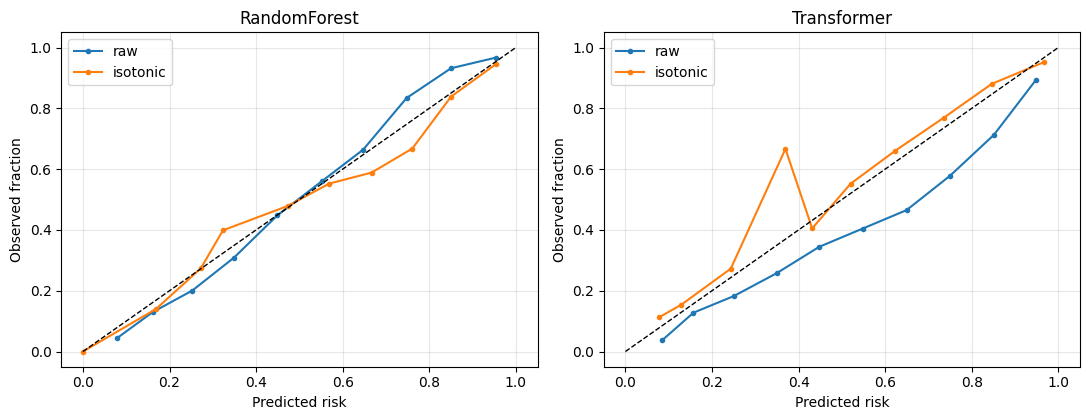

,model,variant,brier,ece,auc
0,RandomForest,raw,0.1807,0.0329,0.7917
1,RandomForest,isotonic,0.1812,0.0256,0.7895
2,Transformer,raw,0.1906,0.0989,0.7912
3,Transformer,isotonic,0.1805,0.0294,0.7873


In [ ]:
def ece(y_true, p, n_bins=10):
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        msk = bins == b
        if msk.sum():
            e += msk.mean() * abs(y_true[msk].mean() - p[msk].mean())
    return e

rf_c = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                              random_state=0, n_jobs=-1)
rf_c.fit(Xtab8.iloc[tr_fit], y8[tr_fit])
cal_preds = {"RandomForest": dict(cal=rf_c.predict_proba(Xtab8.iloc[tr_val])[:, 1],
                                  test=rf_c.predict_proba(Xtab8.iloc[te8])[:, 1]),
             "Transformer": dict(
                 cal=train_seq_seeded("transformer", Xseq8[tr_fit], S8[tr_fit],
                                      y8[tr_fit], Xseq8[tr_val], S8[tr_val], seed=0),
                 test=train_seq_seeded("transformer", Xseq8[tr_fit], S8[tr_fit],
                                       y8[tr_fit], Xseq8[te8], S8[te8], seed=0))}

rows_cal = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (mname, d) in zip(axes, cal_preds.items()):
    iso = IsotonicRegression(out_of_bounds="clip").fit(d["cal"], y8[tr_val])
    for label, pcs in [("raw", d["test"]), ("isotonic", iso.predict(d["test"]))]:
        frac, mp = calibration_curve(yte8, pcs, n_bins=10, strategy="uniform")
        ax.plot(mp, frac, marker="o", ms=3, label=label)
        rows_cal.append(dict(model=mname, variant=label,
                             brier=round(float(np.mean((pcs - yte8) ** 2)), 4),
                             ece=round(float(ece(yte8, pcs)), 4),
                             auc=round(roc_auc_score(yte8, pcs), 4)))
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=mname, xlabel="Predicted risk", ylabel="Observed fraction")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("calibration_week8.png", dpi=300, bbox_inches="tight")
plt.show()
calib = pd.DataFrame(rows_cal)
calib.to_csv("calibration_week8.csv", index=False)
display(calib)

In [ ]:
# --- Save calibration study outputs to Google Drive -------------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "calibration_week8.png",
    "calibration_week8.csv"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("Calibration outputs saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/calibration_week8.png
Saved: /content/drive/MyDrive/SAMayu/calibration_week8.csv
Calibration outputs saved to SAMayu folder.


## 15. Interpretability: RF SHAP + transformer week-occlusion
Both exhibits under the holdout protocol: exact TreeSHAP for the recommended
classical model, and week-occlusion (zero one test week, measure AUC drop,
3 seeds) for the transformer at horizons 8 and 20.

/tmp/ipykernel_6268/3371042330.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample, max_display=15, show=False)


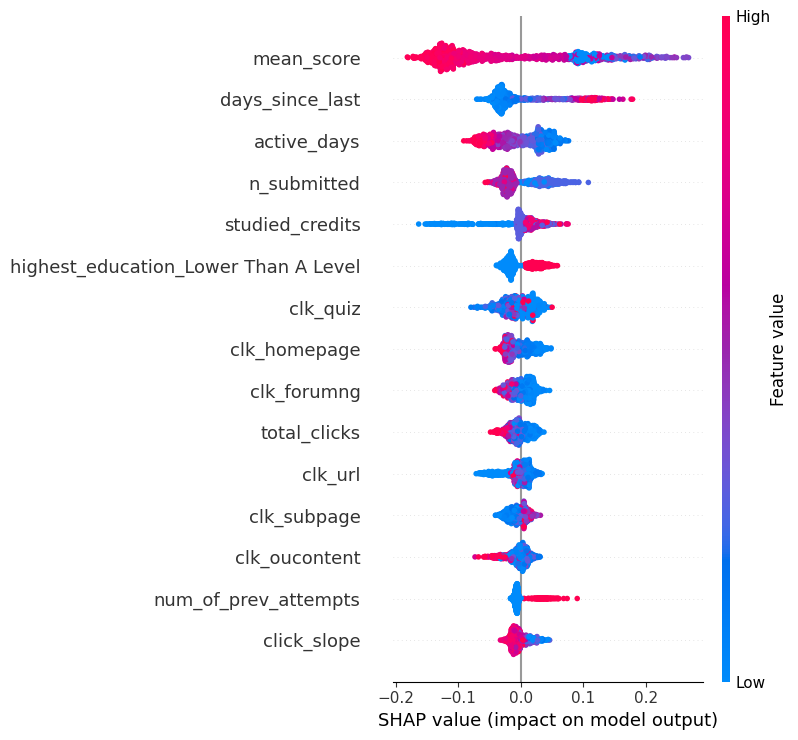

In [ ]:
import shap
rf_shap = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                 random_state=0, n_jobs=-1)
rf_shap.fit(Xtab8.iloc[tr8], y8[tr8])
sample = Xtab8.iloc[te8].sample(1000, random_state=0)
sv = shap.TreeExplainer(rf_shap).shap_values(sample)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[..., 1]
shap.summary_plot(sv, sample, max_display=15, show=False)
plt.savefig("shap_week8_rf_holdout.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# --- Save SHAP output to Google Drive --------------------------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "shap_week8_rf_holdout.png"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("SHAP output saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/shap_week8_rf_holdout.png
SHAP output saved to SAMayu folder.


horizon 8 occlusion done
horizon 20 occlusion done


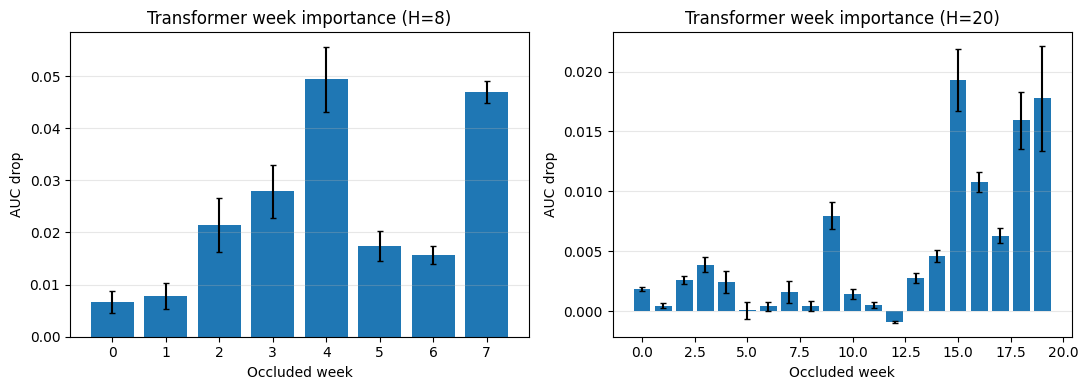

In [ ]:
occ_rows = []
for H_ in [8, 20]:
    if H_ == 8:
        coh, trh, teh, Xq, Sh, yh = cohort8, tr8, te8, Xseq8, S8, y8
    else:
        hd = H_ * 7
        coh = df[df.date_unregistration.isna() | (df.date_unregistration >= hd)]
        coh = coh.reset_index(drop=True)
        trh = np.where(coh.code_presentation.isin(TRAIN_PRES))[0]
        teh = np.where(coh.code_presentation.isin(TEST_PRES))[0]
        _, yh = build_tabular(H_, coh)
        Xq = build_sequences_v3(H_, coh)
        Sh = StandardScaler().fit(build_static(coh)[trh]) \
                             .transform(build_static(coh)).astype(np.float32)
    yteh = yh[teh]
    xte_t = torch.tensor(Xq[teh]).to(DEVICE)
    ste_t = torch.tensor(Sh[teh]).to(DEVICE)
    for s in [0, 1, 2]:
        model = train_seq_seeded("transformer", Xq[trh], Sh[trh], yh[trh],
                                 None, None, seed=s, return_model=True)
        with torch.no_grad():
            base_auc = roc_auc_score(yteh,
                torch.sigmoid(model(xte_t, ste_t)).cpu().numpy())
        for w in range(H_):
            x_occ = xte_t.clone()
            x_occ[:, w, :] = 0.0
            with torch.no_grad():
                auc_w = roc_auc_score(yteh,
                    torch.sigmoid(model(x_occ, ste_t)).cpu().numpy())
            occ_rows.append(dict(horizon=H_, seed=s, week=w,
                                 auc_drop=round(base_auc - auc_w, 5)))
    print(f"horizon {H_} occlusion done")

occ = pd.DataFrame(occ_rows)
occ.to_csv("week_occlusion.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, H_ in zip(axes, [8, 20]):
    g = occ[occ.horizon == H_].groupby("week").auc_drop.agg(["mean", "std"]).reset_index()
    ax.bar(g.week, g["mean"], yerr=g["std"], capsize=2)
    ax.set(xlabel="Occluded week", ylabel="AUC drop",
           title=f"Transformer week importance (H={H_})")
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("week_occlusion.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# --- Save week occlusion outputs to Google Drive ----------------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "week_occlusion.csv",
    "week_occlusion.png"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("Week occlusion outputs saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/week_occlusion.csv
Saved: /content/drive/MyDrive/SAMayu/week_occlusion.png
Week occlusion outputs saved to SAMayu folder.


## 16. Error analysis (week 8): consensus misses + false positives
All-model agreement at the 25% budget: profile of at-risk students no model
flags (the behavioral ceiling) and of not-at-risk students every model flags
(the alert-budget cost side).

In [ ]:
k = max(1, int(ALERT_RATE * len(yte8)))
flag_sets = {m: set(np.argsort(avg8[m])[::-1][:k]) for m in MODELS6}
feat_te = Xtab8.iloc[te8].reset_index(drop=True)
meta_te = cohort8.iloc[te8][["final_result"]].reset_index(drop=True)
FEATS = ["total_clicks", "active_days", "days_since_last", "mean_score", "n_submitted"]

def n_flagging(idx_set):
    return np.array([sum(i in flag_sets[m] for m in MODELS6) for i in idx_set])

ar = np.where(yte8 == 1)[0]
nf = n_flagging(ar)
groups = {"missed_by_all": ar[nf == 0],
          "caught_by_some": ar[(nf > 0) & (nf < len(MODELS6))],
          "caught_by_all": ar[nf == len(MODELS6)]}
rows_ea = []
for gname, idx in groups.items():
    row = {"group": gname, "n": len(idx),
           "pct_withdrawn": round((meta_te.final_result.iloc[idx] == "Withdrawn").mean() * 100, 1)}
    for f in FEATS:
        row[f] = round(float(feat_te[f].iloc[idx].mean()), 2)
    rows_ea.append(row)
ea = pd.DataFrame(rows_ea).set_index("group")
ea.to_csv("error_analysis_week8.csv")
print(f"At-risk missed by ALL models: {len(groups['missed_by_all']):,}"
      f"/{len(ar):,} ({100*len(groups['missed_by_all'])/len(ar):.1f}%)")
display(ea)

safe = np.where(yte8 == 0)[0]
nfs = n_flagging(safe)
fp_all = safe[nfs == len(MODELS6)]
prof = pd.DataFrame({"consensus_FP": feat_te.iloc[fp_all][FEATS].mean().round(2),
                     "all_not_at_risk": feat_te.iloc[safe][FEATS].mean().round(2)})
prof.to_csv("error_analysis_week8_fp.csv")
print(f"\nConsensus false positives: {len(fp_all):,}/{len(safe):,} "
      f"({100*len(fp_all)/len(safe):.1f}%)")
display(prof)

At-risk missed by ALL models: 2,106/6,283 (33.5%)


,n,pct_withdrawn,total_clicks,active_days,days_since_last,mean_score,n_submitted
group,,,,,,,
missed_by_all,2106,43.4,533.65,25.22,4.48,78.29,2.02
caught_by_some,2442,37.8,311.83,16.34,11.61,50.81,1.44
caught_by_all,1735,36.7,131.55,8.03,29.07,22.79,0.72



Consensus false positives: 151/8,815 (1.7%)


,consensus_FP,all_not_at_risk
total_clicks,156.050003,645.799988
active_days,9.780000,27.580000
days_since_last,18.010000,4.750000
mean_score,33.439999,74.330002
n_submitted,1.250000,1.950000


In [ ]:
# --- Save error analysis outputs to Google Drive ----------------------------

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/SAMayu"
os.makedirs(SAVE_DIR, exist_ok=True)

files_to_save = [
    "error_analysis_week8.csv",
    "error_analysis_week8_fp.csv"
]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(SAVE_DIR, f))
        print(f"Saved: {os.path.join(SAVE_DIR, f)}")
    else:
        print(f"Not found: {f}")

print("Error analysis outputs saved to SAMayu folder.")

Saved: /content/drive/MyDrive/SAMayu/error_analysis_week8.csv
Saved: /content/drive/MyDrive/SAMayu/error_analysis_week8_fp.csv
Error analysis outputs saved to SAMayu folder.


## 17. Output manifest (commit all of these to the repo)

| artifact | manuscript destination |
|---|---|
| `results_6models.csv` | Tables I-II, all in-text metrics |
| `corrected_stats_full.csv` | Sec. IV-A primary inference [P1] |
| `cluster_bootstrap_week8.csv` | Sec. III-E sensitivity [P4] |
| `tuning_check_week8.csv`, `tuned_significance_week8.csv` | tuning paragraph [P2] |
| `representation_study_week8.csv` | Table III |
| `fairness_week8.csv` | fairness sentences [P3] |
| `calibration_week8.csv/.png` | Sec. IV-C |
| `earliness_figure.png`, `budget_curves.png`, `topk_budget_curves.csv` | Figs. 1-2 |
| `shap_week8_rf_holdout.png` | Fig. 3 [P6] |
| `week_occlusion.csv/.png` | Fig. 4 |
| `error_analysis_week8.csv`, `..._fp.csv` | Sec. IV-D |

Seed-averaged Friedman statistics [P5] are in this notebook's Section 10
printout. This notebook is the version of record; the earlier patch-stack
notebooks are superseded and can be archived.


In [ ]:
# 18. Naive-protocol factorial: {random split, year-ahead} x {clickstream-only, full info}
# Reuses week-8 context (Sec. 9) and CLICK_COLS/S0 (Sec. 13). No re-run of Secs. 0-17 needed.

# --- one fixed random 80/20 split, pooling both years (the "naive" split) ---
idx_all = np.arange(len(cohort8))
tr_rand, te_rand = train_test_split(idx_all, test_size=0.2, random_state=42,
                                     stratify=y8)
yte_rand = y8[te_rand]
print(f"Naive random split: train={len(tr_rand):,} test={len(te_rand):,} "
      f"at-risk train={y8[tr_rand].mean():.3f} test={yte_rand.mean():.3f}")

FULL_COLS = list(Xtab8.columns)   # classical "full info" = all engineered features

def fit_rf_auc(cols, tr_idx, te_idx, seed):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                 random_state=seed, n_jobs=-1)
    rf.fit(Xtab8[cols].iloc[tr_idx], y8[tr_idx])
    p = rf.predict_proba(Xtab8[cols].iloc[te_idx])[:, 1]
    return roc_auc_score(y8[te_idx], p)

def fit_transformer_auc(clickstream_only, tr_idx, te_idx, seed):
    Xv = Xseq8.copy()
    Sv = S8
    if clickstream_only:
        Xv[:, :, N_CLICK_CH:] = 0.0   # zero assessment channels
        Sv = S0                        # zero demographics (matches Sec. 13 "C only")
    p = train_seq_seeded("transformer", Xv[tr_idx], Sv[tr_idx], y8[tr_idx],
                          Xv[te_idx], Sv[te_idx], seed=seed)
    return roc_auc_score(y8[te_idx], p)

naive_rows = []
for seed in SEEDS:
    # random split x full info
    naive_rows.append(dict(split="random", info="full", model="RandomForest",
                            seed=seed, auc=fit_rf_auc(FULL_COLS, tr_rand, te_rand, seed)))
    naive_rows.append(dict(split="random", info="full", model="Transformer",
                            seed=seed, auc=fit_transformer_auc(False, tr_rand, te_rand, seed)))
    # random split x clickstream-only  <-- this is the "naive protocol" cell
    naive_rows.append(dict(split="random", info="clickstream_only", model="RandomForest",
                            seed=seed, auc=fit_rf_auc(CLICK_COLS, tr_rand, te_rand, seed)))
    naive_rows.append(dict(split="random", info="clickstream_only", model="Transformer",
                            seed=seed, auc=fit_transformer_auc(True, tr_rand, te_rand, seed)))
    print(f"  seed {seed} done")

naive_df = pd.DataFrame(naive_rows)
naive_df.to_csv("naive_protocol_random_split.csv", index=False)

# --- pull the two year-ahead cells already computed (Sec. 8 Table I, Sec. 13 "C only") ---
yearahead_full = dict(RandomForest=summary.query("model=='RandomForest' and week==8").auc_mean.values[0],
                       Transformer=summary.query("model=='Transformer' and week==8").auc_mean.values[0])
yearahead_click = dict(RandomForest=rep.query("model=='RandomForest' and variant=='C only'").auc.values[0],
                        Transformer=rep.query("model=='Transformer' and variant=='C only'").auc.values[0])

# --- assemble the 2x2 factorial table ---
factorial = pd.DataFrame({
    ("clickstream_only", "RandomForest"): [yearahead_click["RandomForest"],
                                            naive_df.query("info=='clickstream_only' and model=='RandomForest'").auc.mean()],
    ("clickstream_only", "Transformer"):  [yearahead_click["Transformer"],
                                            naive_df.query("info=='clickstream_only' and model=='Transformer'").auc.mean()],
    ("full_info", "RandomForest"):        [yearahead_full["RandomForest"],
                                            naive_df.query("info=='full' and model=='RandomForest'").auc.mean()],
    ("full_info", "Transformer"):         [yearahead_full["Transformer"],
                                            naive_df.query("info=='full' and model=='Transformer'").auc.mean()],
}, index=["year_ahead", "random_split"]).round(4)

factorial.to_csv("protocol_factorial_week8.csv")
print("\nProtocol factorial (week 8, AUC):")
display(factorial)

NameError: name 'np' is not defined